# Feature Selection Results — For Paper
**LEAF Framework · Section 3.4: Feature Selection**

4-step pipeline: Spearman → Mutual Information → GBM Importance → Walk-forward Stability  
Train only: 2013-01-02 → 2022-06-30 · 35 candidates → 7 predictor + 4 forced = 11 features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

ROOT     = Path('../../')
RPT_PATH = ROOT / 'data/processed/v2/feature_selection_report.csv'
FIG_DIR  = ROOT / 'notebooks/eda/figures'
FIG_DIR.mkdir(exist_ok=True)

COLORS = {
    'selected':  '#2ecc71',
    'forced':    '#3498db',
    'rejected':  '#bdc3c7',
    'macro':     '#9b59b6',
}

report = pd.read_csv(RPT_PATH)
print(f'Loaded: {RPT_PATH.name} | {len(report)} features')
report.head(3)

Loaded: feature_selection_report.csv | 35 features


,feature,spearman_corr,spearman_pval,spearman_pass,mi_score,mi_pass,shap_importance,stability_mean,stability_std,stability_score,selected_predictor,force_included,selected_regime
0,vnm_ret,0.076703,2.216102e-40,True,0.047521,True,0.220396,0.161954,0.014345,11.289593,True,False,True
1,vnm_ret_streak,0.073129,7.470812e-37,True,0.010674,False,0.000000,NaN,NaN,NaN,False,False,False
2,risk_off_composite,-0.070463,2.485927e-34,True,0.049944,True,0.153698,0.151656,0.030302,5.004865,True,False,True


---
## Section 1 · Pipeline Funnel
*(Paper: Figure 3.X — 35 → 12 → 7 → 7 → 11)*

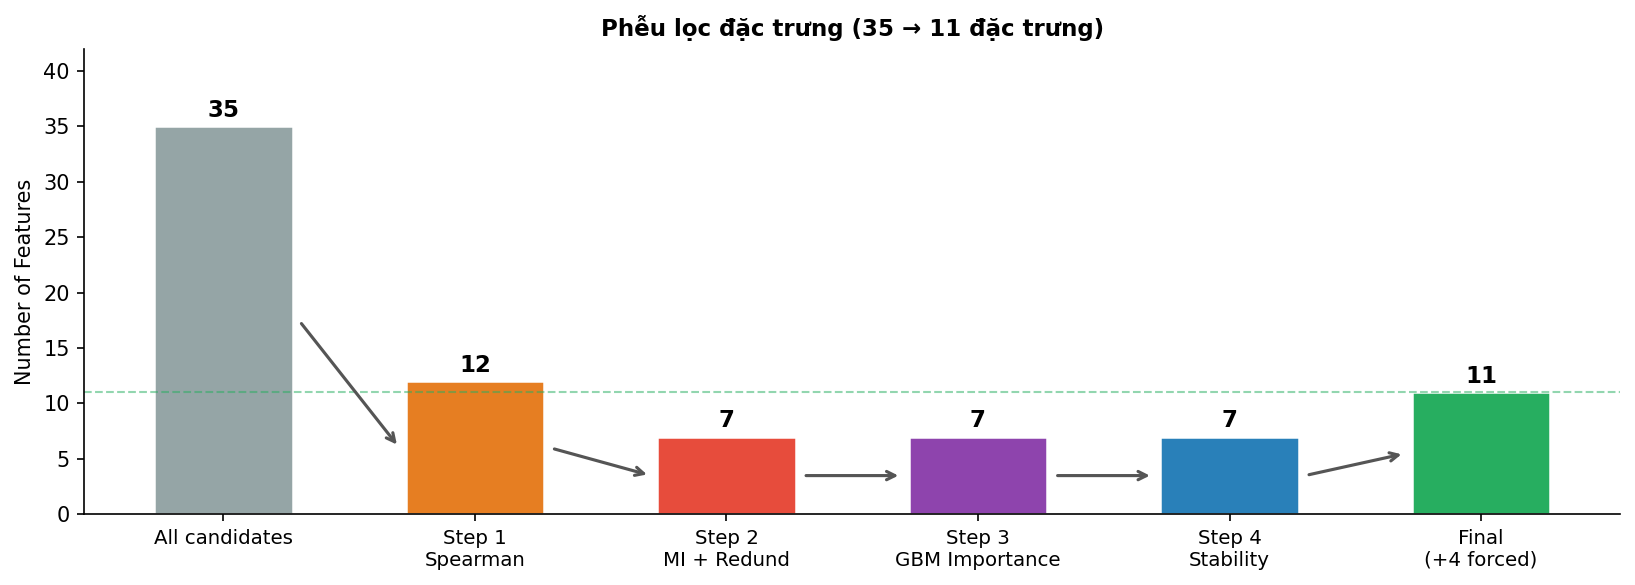

In [12]:
steps = [
    ('All candidates',      35,  '#95a5a6'),
    ('Step 1\nSpearman',   12,  '#e67e22'),
    ('Step 2\nMI + Redund', 7,  '#e74c3c'),
    ('Step 3\nGBM Importance', 7, '#8e44ad'),
    ('Step 4\nStability',   7,  '#2980b9'),
    ('Final\n(+4 forced)', 11,  '#27ae60'),
]

fig, ax = plt.subplots(figsize=(11, 4))
xs = np.arange(len(steps))
bar_h = [s[1] for s in steps]
bar_c = [s[2] for s in steps]
labels = [s[0] for s in steps]

bars = ax.bar(xs, bar_h, color=bar_c, width=0.55, edgecolor='white', linewidth=1.2)

for bar, h in zip(bars, bar_h):
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.4, str(h),
            ha='center', va='bottom', fontweight='bold', fontsize=11)

# Arrows between bars
for i in range(len(steps) - 1):
    ax.annotate('', xy=(xs[i+1] - 0.3, bar_h[i+1]/2),
                xytext=(xs[i] + 0.3, bar_h[i]/2),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.5))

ax.set_xticks(xs)
ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylabel('Number of Features')
ax.set_ylim(0, 42)
ax.set_title('Phễu lọc đặc trưng (35 → 11 đặc trưng)', fontweight='bold')
ax.axhline(11, color='#27ae60', linewidth=1, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_fs_funnel.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 2 · Spearman Correlation — All 35 Features
*(Paper: Figure 3.X — Step 1 results)*

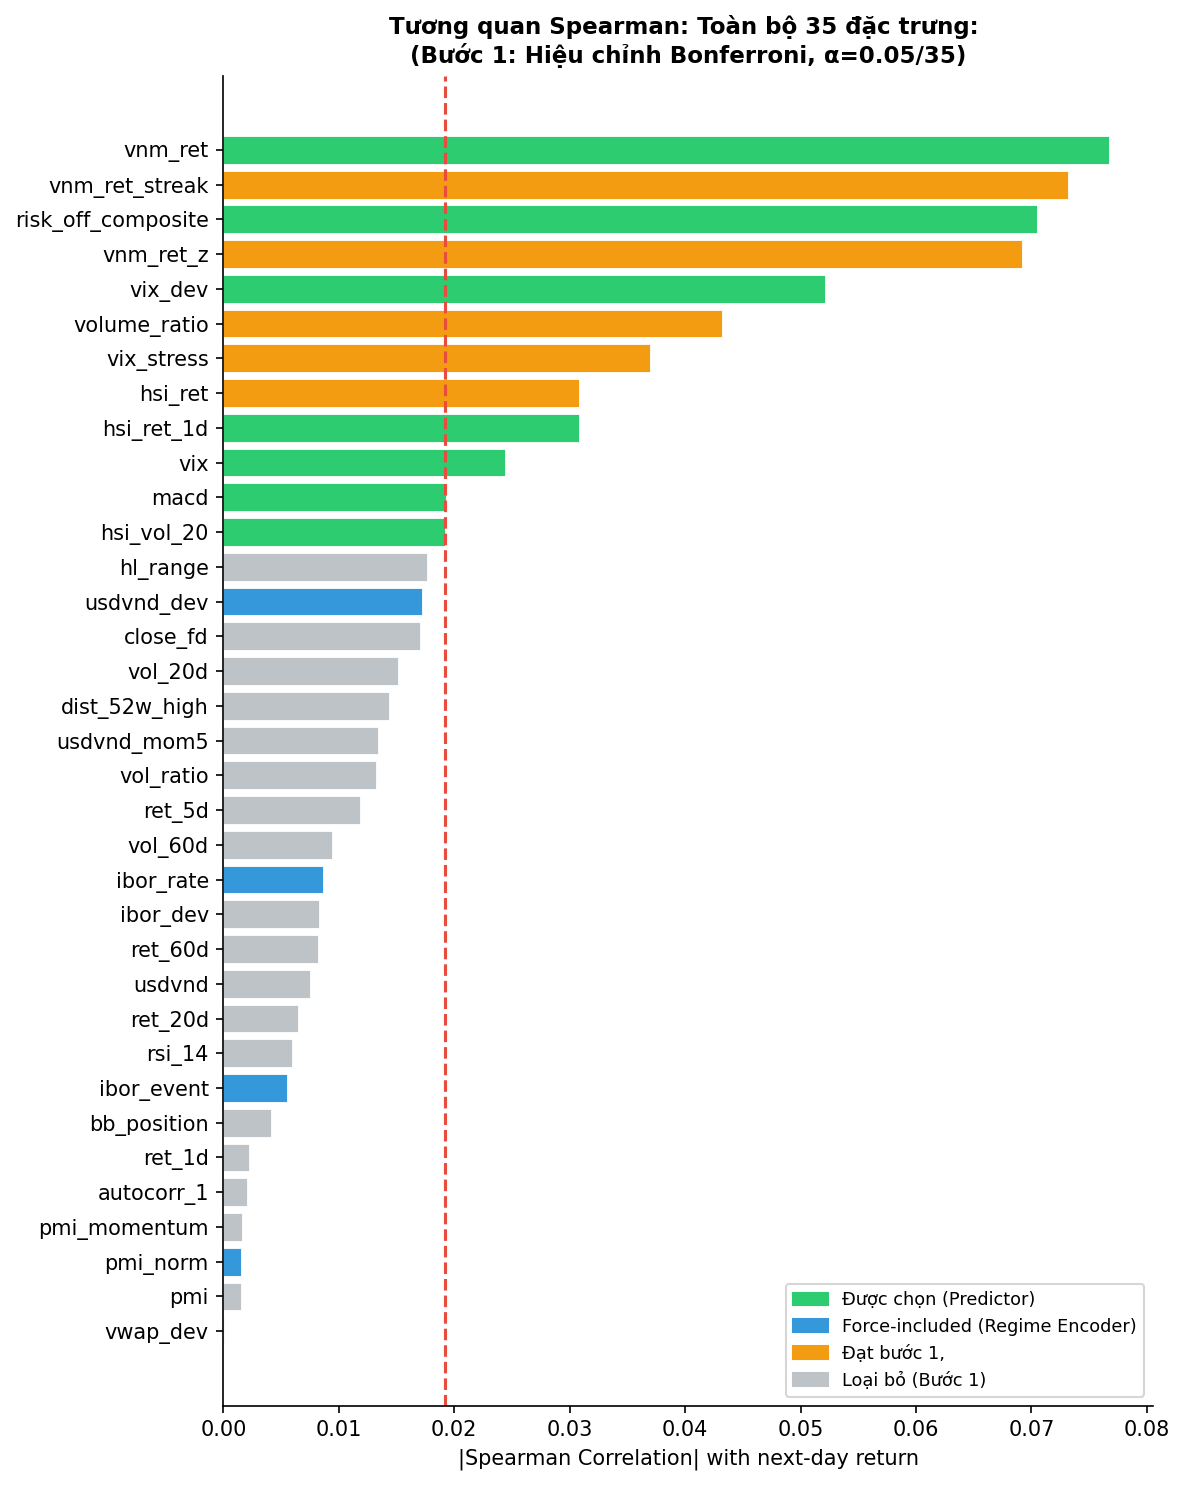

In [14]:
df = report.sort_values('spearman_corr', key=abs, ascending=True).copy()

def feature_color(row):
    if row['force_included']:  return COLORS['forced']
    if row['selected_predictor']: return COLORS['selected']
    if row['spearman_pass']:   return '#f39c12'
    return COLORS['rejected']

colors = df.apply(feature_color, axis=1)

fig, ax = plt.subplots(figsize=(8, 10))
bars = ax.barh(df['feature'], df['spearman_corr'].abs(), color=colors, edgecolor='white', linewidth=0.4)

# Bonferroni threshold line
alpha_bonf = 0.05 / 35
# Convert p-value threshold to |corr| threshold is hard, so just shade the passing region
pass_min = df[df['spearman_pass']]['spearman_corr'].abs().min()
ax.axvline(pass_min, color='#e74c3c', linewidth=1.5, linestyle='--',
           label=f'Bonferroni threshold (α={alpha_bonf:.4f})')

patches = [
    mpatches.Patch(color=COLORS['selected'],  label='Được chọn (Predictor)'),
    mpatches.Patch(color=COLORS['forced'],    label='Force-included (Regime Encoder)'),
    mpatches.Patch(color='#f39c12',           label='Đạt bước 1,'),
    mpatches.Patch(color=COLORS['rejected'],  label='Loại bỏ (Bước 1)'),
]
ax.legend(handles=patches, loc='lower right', fontsize=8.5)
ax.set_xlabel('|Spearman Correlation| with next-day return')
ax.set_title('Tương quan Spearman: Toàn bộ 35 đặc trưng: \n(Bước 1: Hiệu chỉnh Bonferroni, α=0.05/35)',
             fontweight='bold')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_fs_spearman.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 3 · GBM Importance vs Stability (7 surviving features)
*(Paper: Figure 3.X — Step 3 & 4 combined)*

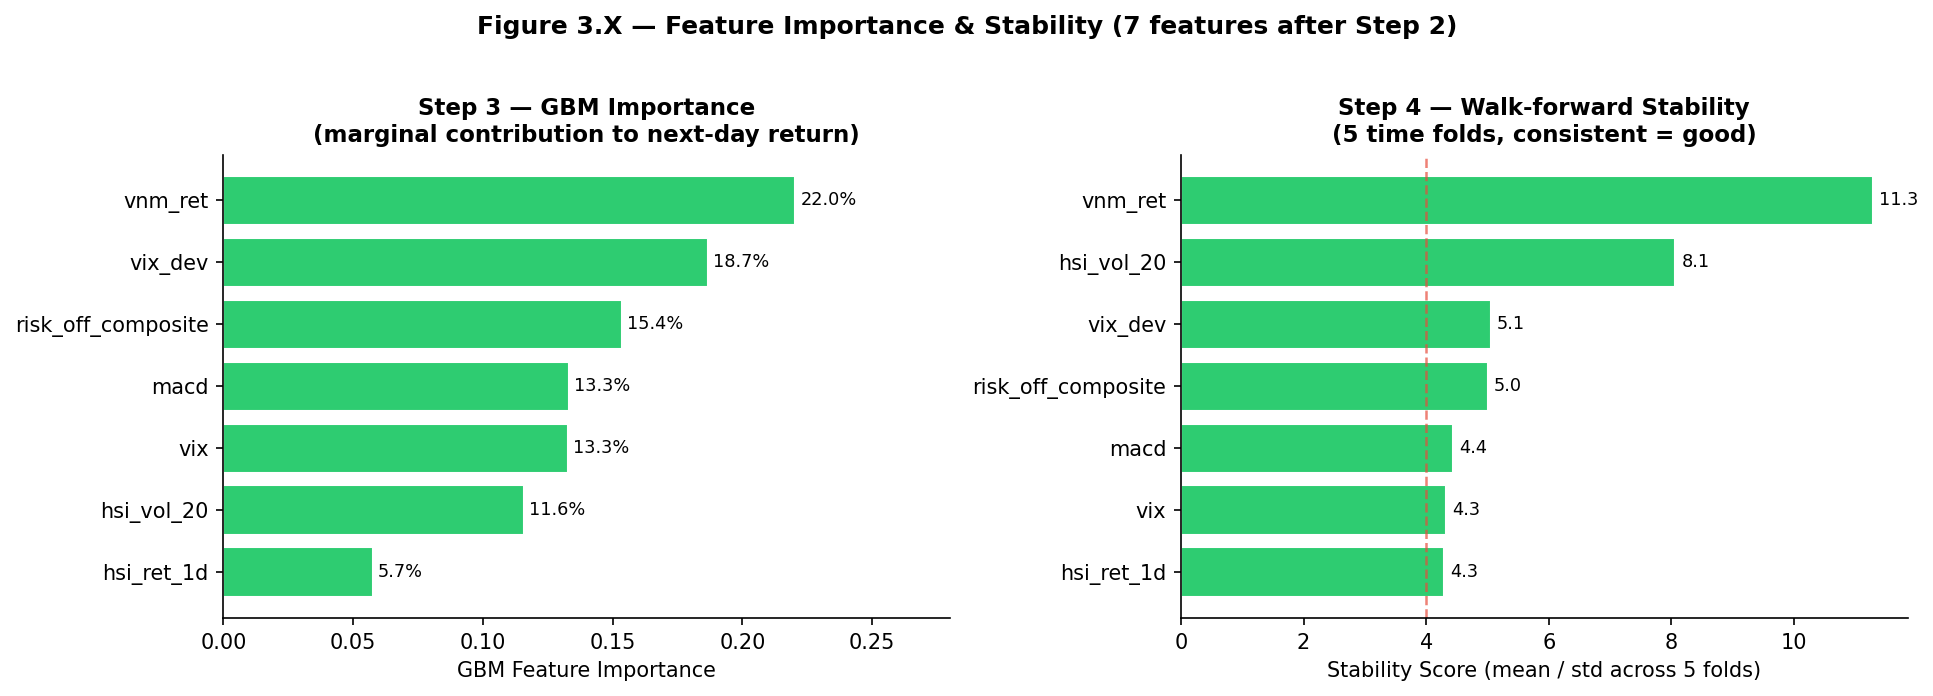

In [4]:
sel = report[report['mi_pass']].copy().sort_values('shap_importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ── Left: GBM Importance ──
ax = axes[0]
c = [COLORS['selected']] * len(sel)
bars = ax.barh(sel['feature'][::-1], sel['shap_importance'][::-1],
               color=c[::-1], edgecolor='white')
for bar, v in zip(bars, sel['shap_importance'][::-1]):
    ax.text(v + 0.002, bar.get_y() + bar.get_height()/2,
            f'{v:.1%}', va='center', fontsize=8.5)
ax.set_xlabel('GBM Feature Importance')
ax.set_title('Step 3 — GBM Importance\n(marginal contribution to next-day return)', fontweight='bold')
ax.set_xlim(0, 0.28)

# ── Right: Stability Score ──
ax = axes[1]
sel_stab = sel.sort_values('stability_score', ascending=False)
bar_colors = ['#e74c3c' if s < 4 else COLORS['selected'] for s in sel_stab['stability_score']]
bars = ax.barh(sel_stab['feature'][::-1], sel_stab['stability_score'][::-1],
               color=bar_colors[::-1], edgecolor='white')
for bar, v in zip(bars, sel_stab['stability_score'][::-1]):
    ax.text(v + 0.1, bar.get_y() + bar.get_height()/2,
            f'{v:.1f}', va='center', fontsize=8.5)
ax.axvline(4, color='#e74c3c', linewidth=1.2, linestyle='--', alpha=0.7, label='Min threshold')
ax.set_xlabel('Stability Score (mean / std across 5 folds)')
ax.set_title('Step 4 — Walk-forward Stability\n(5 time folds, consistent = good)', fontweight='bold')

fig.suptitle('Figure 3.X — Feature Importance & Stability (7 features after Step 2)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_fs_importance_stability.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 4 · Final 11 Features Summary Table
*(Paper: Table 3.X — Selected features with scores)*

In [5]:
final = report[report['selected_regime']].copy()

# Label feature type
def ftype(row):
    if row['force_included']: return 'Macro (forced)'
    feat = row['feature']
    if feat in ['macd']: return 'Technical'
    return 'Macro / External'

final['type'] = final.apply(ftype, axis=1)
final['used_in'] = final.apply(
    lambda r: 'Predictor + Regime Encoder' if r['selected_predictor'] else 'Regime Encoder only',
    axis=1
)

display_cols = ['feature', 'type', 'spearman_corr', 'mi_score', 'shap_importance', 'stability_score', 'used_in']
final_display = final[display_cols].copy()
final_display.columns = ['Feature', 'Type', 'Spearman', 'MI Score', 'GBM Imp.', 'Stability', 'Used In']

# Sort: predictor first, then forced
order = ['Predictor + Regime Encoder', 'Regime Encoder only']
final_display['_sort'] = final_display['Used In'].map({v: i for i, v in enumerate(order)})
final_display = final_display.sort_values(['_sort', 'GBM Imp.'], ascending=[True, False]).drop('_sort', axis=1)

print(final_display.to_string(index=False))
final_display

           Feature             Type  Spearman  MI Score  GBM Imp.  Stability                    Used In
           vnm_ret Macro / External  0.076703  0.047521  0.220396  11.289593 Predictor + Regime Encoder
           vix_dev Macro / External -0.052108  0.045023  0.186829   5.055882 Predictor + Regime Encoder
risk_off_composite Macro / External -0.070463  0.049944  0.153698   5.004865 Predictor + Regime Encoder
              macd        Technical  0.019324  0.038534  0.133063   4.442392 Predictor + Regime Encoder
               vix Macro / External -0.024356  0.051507  0.132608   4.323989 Predictor + Regime Encoder
        hsi_vol_20 Macro / External -0.019158  0.042961  0.115926   8.068208 Predictor + Regime Encoder
        hsi_ret_1d Macro / External  0.030830  0.038715  0.057480   4.293505 Predictor + Regime Encoder
        usdvnd_dev   Macro (forced) -0.017197  0.000000  0.000000        NaN        Regime Encoder only
         ibor_rate   Macro (forced) -0.008663  0.000000  0.00000

,Feature,Type,Spearman,MI Score,GBM Imp.,Stability,Used In
0,vnm_ret,Macro / External,0.076703,0.047521,0.220396,11.289593,Predictor + Regime Encoder
4,vix_dev,Macro / External,-0.052108,0.045023,0.186829,5.055882,Predictor + Regime Encoder
2,risk_off_composite,Macro / External,-0.070463,0.049944,0.153698,5.004865,Predictor + Regime Encoder
10,macd,Technical,0.019324,0.038534,0.133063,4.442392,Predictor + Regime Encoder
9,vix,Macro / External,-0.024356,0.051507,0.132608,4.323989,Predictor + Regime Encoder
11,hsi_vol_20,Macro / External,-0.019158,0.042961,0.115926,8.068208,Predictor + Regime Encoder
8,hsi_ret_1d,Macro / External,0.030830,0.038715,0.057480,4.293505,Predictor + Regime Encoder
13,usdvnd_dev,Macro (forced),-0.017197,0.000000,0.000000,NaN,Regime Encoder only
21,ibor_rate,Macro (forced),-0.008663,0.000000,0.000000,NaN,Regime Encoder only
27,ibor_event,Macro (forced),0.005505,0.000000,0.000000,NaN,Regime Encoder only


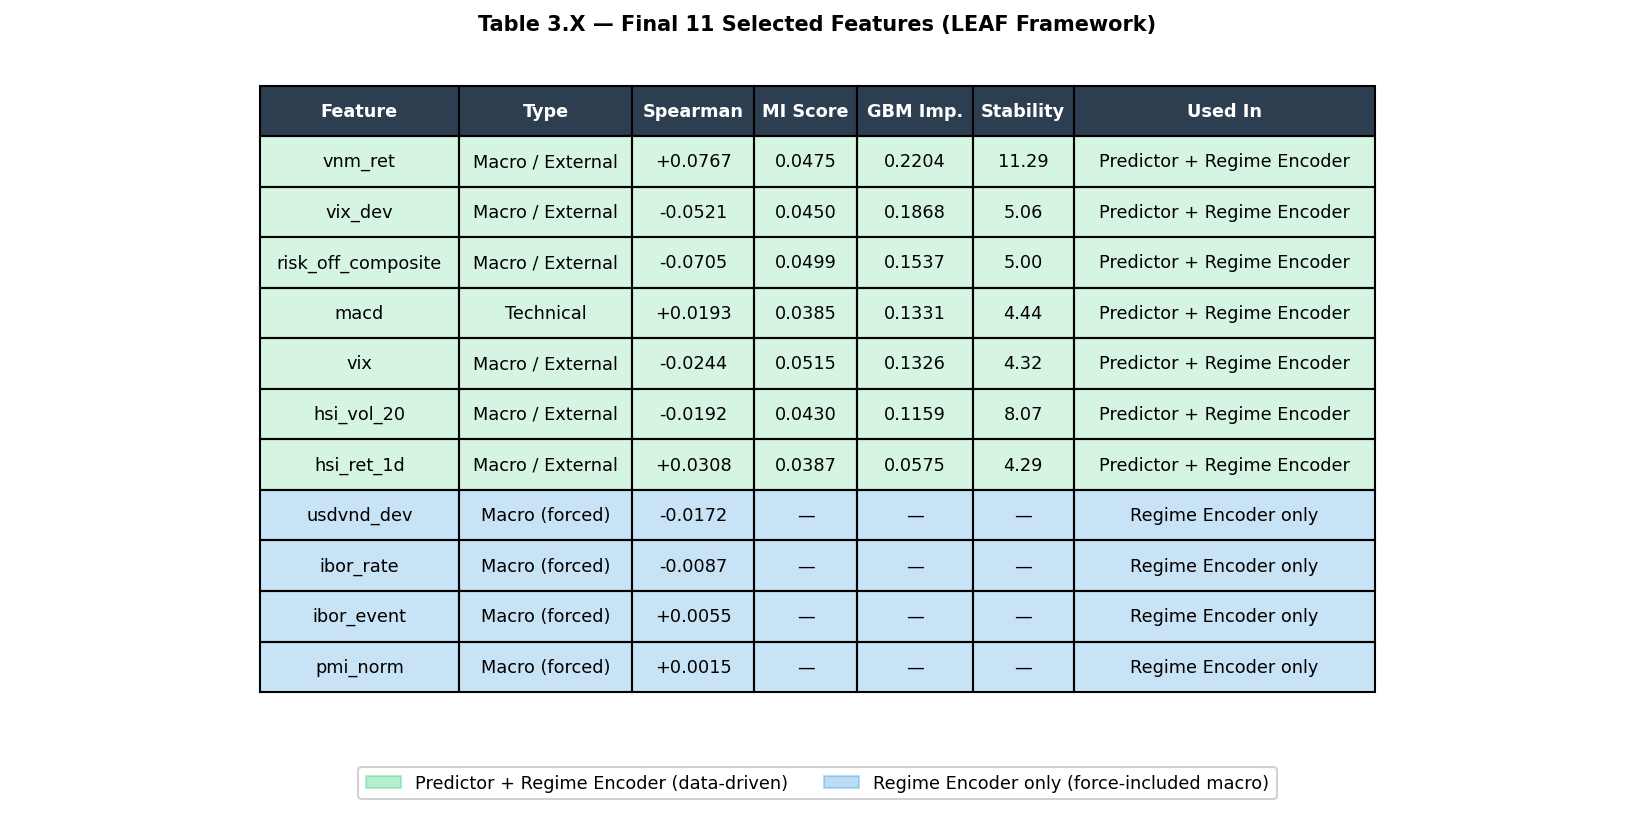

In [8]:
# Styled table for paper
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axis('off')

col_labels = ['Feature', 'Type', 'Spearman', 'MI Score', 'GBM Imp.', 'Stability', 'Used In']
cell_data = []
row_colors_list = []

for _, row in final_display.iterrows():
    cell_data.append([
        row['Feature'],
        row['Type'],
        f"{row['Spearman']:+.4f}",
        f"{row['MI Score']:.4f}" if pd.notna(row['MI Score']) and row['MI Score'] > 0 else '—',
        f"{row['GBM Imp.']:.4f}" if pd.notna(row['GBM Imp.']) and row['GBM Imp.'] > 0 else '—',
        f"{row['Stability']:.2f}" if pd.notna(row['Stability']) and row['Stability'] > 0 else '—',
        row['Used In'],
    ])
    if row['Used In'] == 'Regime Encoder only':
        row_colors_list.append([COLORS['forced'] + '44'] * len(col_labels))
    else:
        row_colors_list.append([COLORS['selected'] + '33'] * len(col_labels))

tbl = ax.table(
    cellText=cell_data, colLabels=col_labels,
    cellLoc='center', loc='center',
    cellColours=row_colors_list,
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1, 1.9)
tbl.auto_set_column_width([0, 1, 2, 3, 4, 5, 6])

for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#2c3e50')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

patches = [
    mpatches.Patch(color=COLORS['selected'] + '55', label='Predictor + Regime Encoder (data-driven)'),
    mpatches.Patch(color=COLORS['forced'] + '55',   label='Regime Encoder only (force-included macro)'),
]
ax.legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, -0.12),
          ncol=2, fontsize=8.5, framealpha=0.9)

plt.title('Table 3.X — Final 11 Selected Features (LEAF Framework)',
          fontsize=10, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(FIG_DIR / 'table_fs_final.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 5 · Feature Type Breakdown
*(Paper: Figure 3.X — 6/7 selected features are macro/external)*

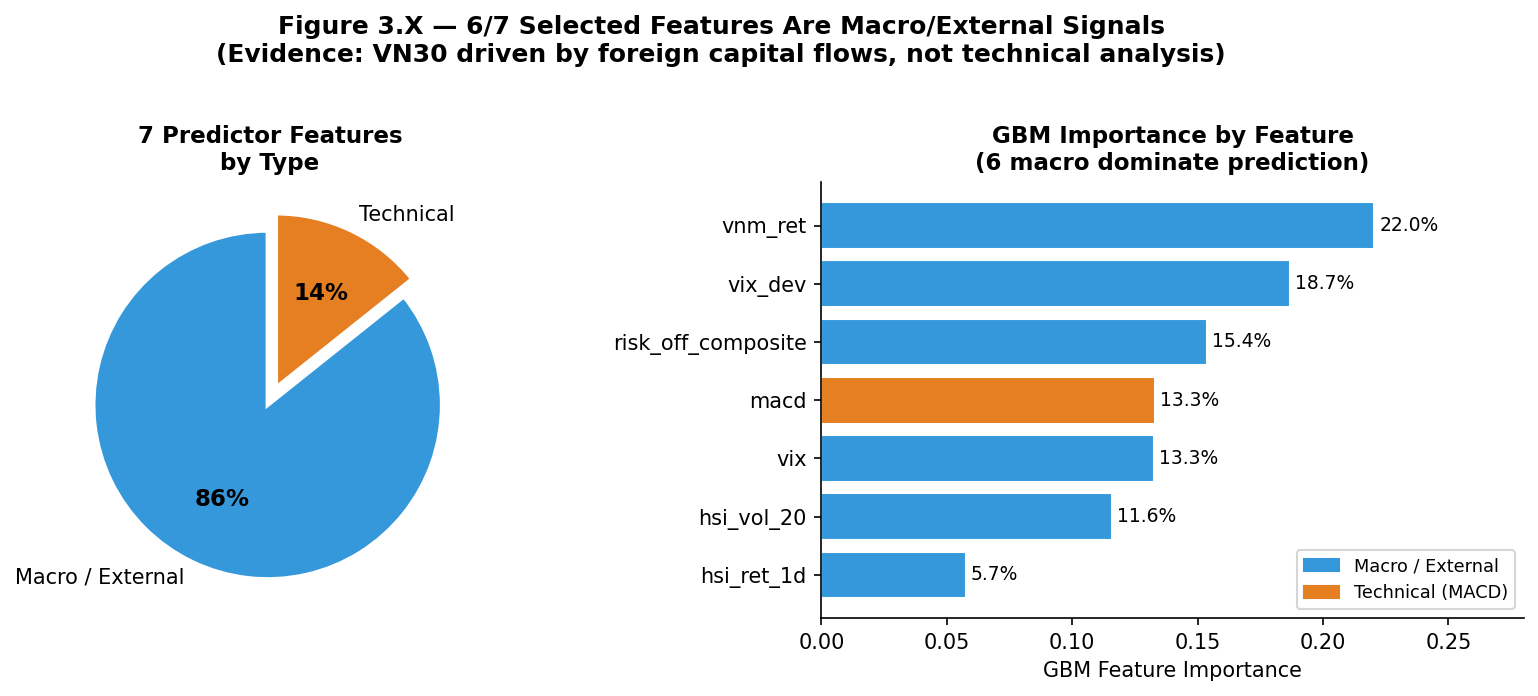

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# ── Left: Pie chart — feature types in final 7 predictor ──
ax = axes[0]
pred_only = report[report['selected_predictor']].copy()

type_counts = {'Macro / External': 6, 'Technical': 1}
wedge_colors = ['#3498db', '#e67e22']
explode = [0.03, 0.08]
wedges, texts, autotexts = ax.pie(
    type_counts.values(), labels=type_counts.keys(),
    colors=wedge_colors, explode=explode,
    autopct='%1.0f%%', startangle=90,
    textprops={'fontsize': 10},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax.set_title('7 Predictor Features\nby Type', fontweight='bold')

# ── Right: Horizontal bar — importance by feature, colored by type ──
ax = axes[1]
pred_sorted = report[report['selected_predictor']].sort_values('shap_importance')
feat_colors = ['#e67e22' if f == 'macd' else '#3498db' for f in pred_sorted['feature']]
bars = ax.barh(pred_sorted['feature'], pred_sorted['shap_importance'],
               color=feat_colors, edgecolor='white')
for bar, v in zip(bars, pred_sorted['shap_importance']):
    ax.text(v + 0.002, bar.get_y() + bar.get_height()/2,
            f'{v:.1%}', va='center', fontsize=9)

patches = [
    mpatches.Patch(color='#3498db', label='Macro / External'),
    mpatches.Patch(color='#e67e22', label='Technical (MACD)'),
]
ax.legend(handles=patches, fontsize=8.5)
ax.set_xlabel('GBM Feature Importance')
ax.set_title('GBM Importance by Feature\n(6 macro dominate prediction)', fontweight='bold')
ax.set_xlim(0, 0.28)

fig.suptitle('Figure 3.X — 6/7 Selected Features Are Macro/External Signals\n'
             '(Evidence: VN30 driven by foreign capital flows, not technical analysis)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_fs_type_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 6 · Step 1 Detail — p-value ranking all 35 features
*(Paper: nếu cần show toàn bộ kết quả Step 1)*

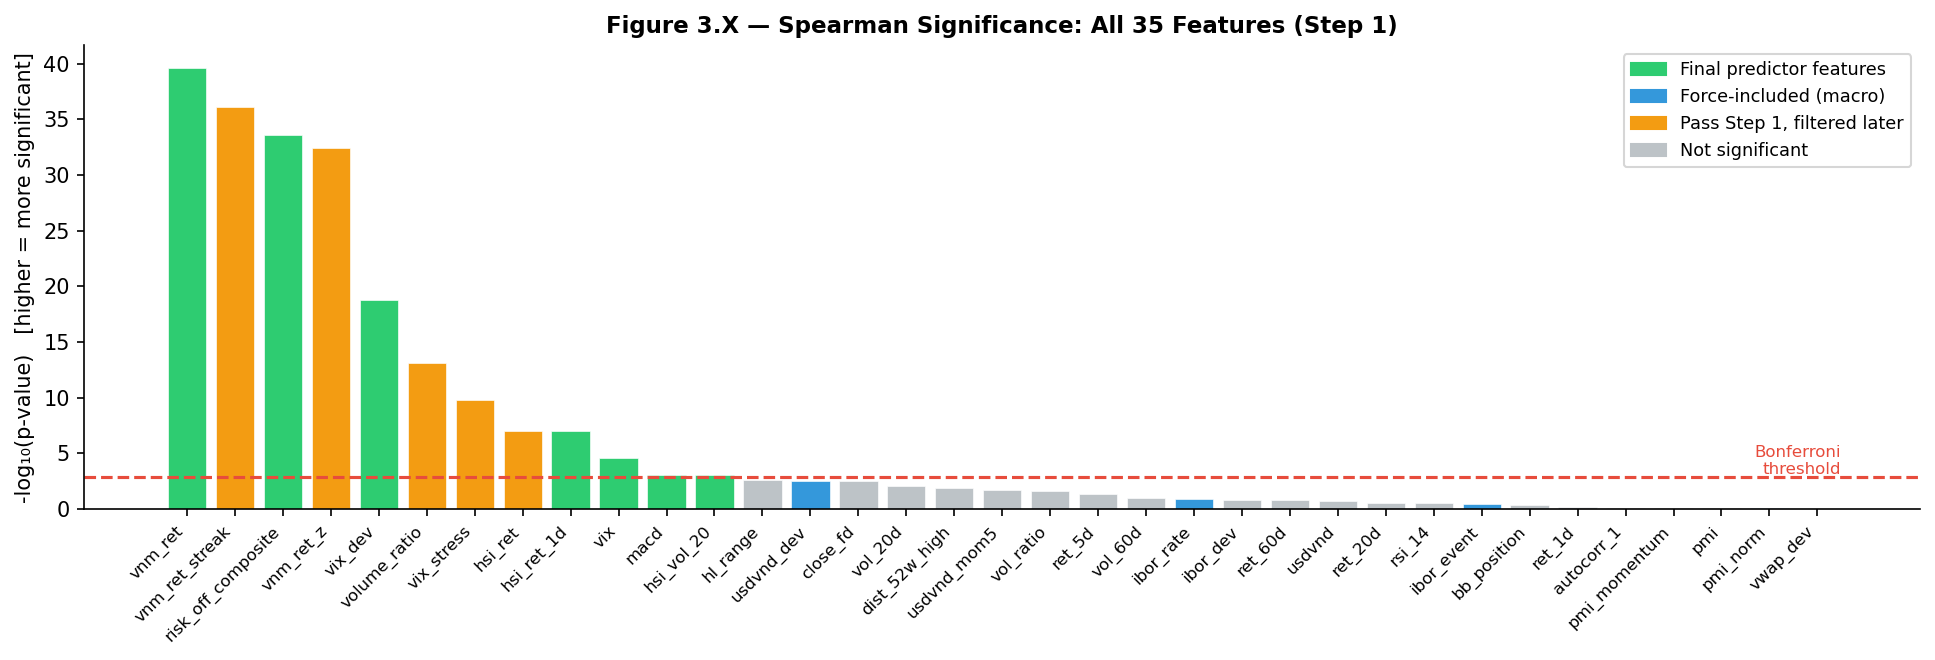

In [11]:
alpha_bonf = 0.05 / 35
df_pval = report.sort_values('spearman_pval').copy()
df_pval['-log10(p)'] = -np.log10(df_pval['spearman_pval'].clip(1e-50))

def pval_color(row):
    if row['force_included']:     return COLORS['forced']
    if row['selected_predictor']: return COLORS['selected']
    if row['spearman_pass']:      return '#f39c12'
    return COLORS['rejected']

pcolors = df_pval.apply(pval_color, axis=1)

fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(df_pval))
bars = ax.bar(x, df_pval['-log10(p)'], color=pcolors, edgecolor='white', linewidth=0.3)

threshold_line = -np.log10(alpha_bonf)
ax.axhline(threshold_line, color='#e74c3c', linewidth=1.5, linestyle='--',
           label=f'Bonferroni threshold (α={alpha_bonf:.4f})')
ax.text(len(df_pval) - 0.5, threshold_line + 0.3, f'Bonferroni\nthreshold',
        ha='right', fontsize=8, color='#e74c3c')

ax.set_xticks(x)
ax.set_xticklabels(df_pval['feature'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('-log₁₀(p-value)   [higher = more significant]')
ax.set_title('Figure 3.X — Spearman Significance: All 35 Features (Step 1)', fontweight='bold')

patches = [
    mpatches.Patch(color=COLORS['selected'],  label='Final predictor features'),
    mpatches.Patch(color=COLORS['forced'],    label='Force-included (macro)'),
    mpatches.Patch(color='#f39c12',           label='Pass Step 1, filtered later'),
    mpatches.Patch(color=COLORS['rejected'],  label='Not significant'),
]
ax.legend(handles=patches, loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig_fs_pvalue.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Summary

| Figure | File | Dùng trong paper |
|--------|------|------------------|
| Figure 3.X | `fig_fs_funnel.png` | Pipeline overview: 35 → 11 |
| Figure 3.X | `fig_fs_spearman.png` | Step 1: Spearman all 35 features |
| Figure 3.X | `fig_fs_importance_stability.png` | Step 3 + 4: Importance & Stability |
| Table 3.X  | `table_fs_final.png` | Final 11 features with scores |
| Figure 3.X | `fig_fs_type_breakdown.png` | 6/7 macro dominance evidence |
| Figure 3.X | `fig_fs_pvalue.png` | Step 1 detail (optional) |

Tất cả figures lưu tại `notebooks/eda/figures/`